# Structured Streaming & Watermarks (Spark)

**Structured Streaming** runs a normal DataFrame query on data that keeps arriving. Spark treats the stream as a
table that grows: every **micro-batch** reads the new rows, updates the result, and writes the changes to a sink.
The same code works for batch and stream. With **event time**, **watermarks** and **checkpoints**, the query gives
correct windows even when events arrive late, and it continues after a restart without loss or duplicates.

M12 Lesson 03 showed these ideas in Flink with Kafka. This lesson uses Spark with a **file source**: Parquet files
that land in a folder, the most common streaming input in a data lake.

**After this lesson you can:**

1. Write an event-time window aggregation with `withWatermark` on a file stream.
2. Explain and measure what the output modes `append`, `update` and `complete` emit.
3. Measure how many late rows a watermark drops, compared with a batch ground truth.
4. Restart a query from its checkpoint and run incremental jobs with `trigger(availableNow=True)`.

**Data:** NYC taxi trips of Wednesday 2024-01-10, 07:00-10:00, delivered as 10-minute Parquet files with
deterministic late arrivals.
**Services:** none (Spark runs locally in the notebook).

In [1]:
import os
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "l08"
shutil.rmtree(WORK, ignore_errors=True)
STAGE = WORK / "staged"                           # files that have not "arrived" yet
STAGE.mkdir(parents=True)

spark = (SparkSession.builder.master("local[4]").appName("m13-l08")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "4")  # 4 state partitions
         .config("spark.ui.showConsoleProgress", "false").config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/17 23:13:14 WARN Utils: Your hostname, Muhammet, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/17 23:13:14 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 23:13:15 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0


## 1. Prepare a Stream of Files with Late Events

The trips of three morning hours are cut into files by **arrival time**: file 0 holds what arrived between 07:00 and
07:10, file 1 the next 10 minutes, and so on. Most trips arrive at their pickup time. A fixed random sample of about 6 % of the trips (755 trips,
seed 7) are delayed by 5 to 60 minutes, for example because the taxi meter was offline. A delayed trip therefore
lands in a later file, among newer trips. The **event time** (`pickup_time`) stays the real pickup time.

In [2]:
raw = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID", "total_amount"])
raw = raw[(raw.tpep_pickup_datetime >= "2024-01-10 07:00") & (raw.tpep_pickup_datetime < "2024-01-10 10:00")]
raw = raw.sort_values(["tpep_pickup_datetime", "PULocationID"]).reset_index(drop=True)
trips = pd.DataFrame({"trip_id": np.arange(len(raw)),
                      "pickup_time": raw.tpep_pickup_datetime.dt.tz_localize("UTC").astype("datetime64[us, UTC]"),
                      "PULocationID": raw.PULocationID.astype("int32"), "total_amount": raw.total_amount})
rng = np.random.default_rng(7)
late = rng.random(len(trips)) < 0.06
delay = pd.Series(pd.to_timedelta(np.where(late, rng.uniform(5, 60, len(trips)), 0.0), unit="min"))
arrival = trips.pickup_time + delay
trips["file_no"] = ((arrival - pd.Timestamp("2024-01-10 07:00", tz="UTC")) // pd.Timedelta(minutes=10)).astype(int)
trips["late_min"] = delay.dt.total_seconds() / 60

for f, part in trips.groupby("file_no"):
    part.drop(columns=["file_no", "late_min"]).to_parquet(STAGE / f"trips-{f:03d}.parquet", index=False)
N_FILES = trips.file_no.nunique()
print(f"{len(trips):,} trips | {late.sum():,} delayed ({100 * late.mean():.1f} %) | {N_FILES} files "
      f"(files 18+ hold only delayed trips) | rows per file: {trips.file_no.value_counts().min():,} - "
      f"{trips.file_no.value_counts().max():,}")

zones = (spark.read.option("header", True).option("inferSchema", True).csv(str(datasets.fetch("taxi_zone_lookup.csv")))
         .select(F.col("LocationID").cast("int").alias("PULocationID"), "Borough"))
borough = zones.toPandas().set_index("PULocationID").Borough

# batch ground truth: trips per 15-minute window and borough, from all trips
truth = (trips.assign(window_start=trips.pickup_time.dt.floor("15min"), Borough=trips.PULocationID.map(borough))
         .groupby(["window_start", "Borough"]).size().rename("trips"))
print(f"ground truth: {len(truth)} (window, borough) rows, {truth.sum():,} trips")

13,169 trips | 755 delayed (5.7 %) | 24 files (files 18+ hold only delayed trips) | rows per file: 4 - 872


ground truth: 63 (window, borough) rows, 13,169 trips


`deliver()` copies staged files into the input folder, as an upstream system would. The file source finds new files
by listing the folder and orders them by modification time; the helper sets increasing times, so the order is
deterministic. `maxFilesPerTrigger=1` makes each file its own micro-batch, as if the files came 10 minutes apart.

In [3]:
SCHEMA = T.StructType([T.StructField("trip_id", T.LongType()), T.StructField("pickup_time", T.TimestampType()),
                       T.StructField("PULocationID", T.IntegerType()), T.StructField("total_amount", T.DoubleType())])

def deliver(folder: Path, files) -> None:
    folder.mkdir(parents=True, exist_ok=True)
    t0 = time.time() - 10_000
    for f in files:
        dst = folder / f"trips-{f:03d}.parquet"
        shutil.copy(STAGE / dst.name, dst)
        os.utime(dst, (t0 + f, t0 + f))           # file f is "older" than file f+1

def windowed(folder: Path, delay: str | None):
    stream = spark.readStream.schema(SCHEMA).option("maxFilesPerTrigger", 1).parquet(str(folder))
    if delay:
        stream = stream.withWatermark("pickup_time", delay)
    return (stream.join(F.broadcast(zones), "PULocationID")              # stream-static join
            .groupBy(F.window("pickup_time", "15 minutes"), "Borough")
            .agg(F.count("*").alias("trips"), F.round(F.sum("total_amount"), 2).alias("revenue"))
            .select(F.col("window.start").alias("window_start"), "Borough", "trips", "revenue"))

def run(name: str, df, mode: str):
    """Run a query until all available files are processed; collect every micro-batch with foreachBatch."""
    out = []
    def sink(batch, batch_id):
        out.append(batch.toPandas().assign(batch_id=batch_id))
    q = (df.writeStream.outputMode(mode).foreachBatch(sink)
         .option("checkpointLocation", str(WORK / "chk" / name)).start())
    q.processAllAvailable()                       # blocks until every file is processed (deterministic runs)
    progress = q.recentProgress
    q.stop()
    emitted = pd.concat(out, ignore_index=True) if out else pd.DataFrame()
    stats = {"query": name, "mode": mode, "batches": len(progress),
             "input rows": sum(p["numInputRows"] for p in progress),
             "rows emitted": len(emitted),
             "dropped late": sum(p["stateOperators"][0].get("numRowsDroppedByWatermark", 0) for p in progress
                                 if p["stateOperators"])}
    return emitted, stats, progress

INPUT = WORK / "input-all"
deliver(INPUT, range(N_FILES))
print(f"{len(list(INPUT.glob('*.parquet')))} files in {INPUT}")

24 files in /tmp/fzth-m13/l08/input-all


## 2. Event-Time Windows and Output Modes

The query counts trips per **15-minute tumbling window** of pickup time and per borough. The **watermark**
`withWatermark("pickup_time", "10 minutes")` tells Spark: *a row that is more than 10 minutes older than the newest
event time seen so far is late; drop it, and treat windows that end before this point as final*. Spark computes the
watermark at the end of each micro-batch and uses it in the next one.

The output mode decides what reaches the sink after each micro-batch:

| mode | emits | state |
| :--- | :--- | :--- |
| `append` | each window **once**, when the watermark passes its end (final value) | removed after emit |
| `update` | only the windows that **changed** in this micro-batch | removed when the watermark passes |
| `complete` | the **whole** result table, every micro-batch | kept forever (no watermark cleanup) |

In [4]:
results, stats = {}, []
for mode in ["append", "update", "complete"]:
    emitted, s, progress = run(f"{mode}-10m", windowed(INPUT, "10 minutes"), mode)
    results[mode] = emitted
    stats.append(s)

def final_view(emitted: pd.DataFrame) -> pd.Series:
    """Latest value per (window, borough): what a table updated by the sink would contain at the end."""
    last = emitted.sort_values("batch_id").groupby(["window_start", "Borough"]).trips.last()
    last.index = last.index.set_levels(pd.to_datetime(last.index.levels[0], utc=True), level=0)
    return last

for s in stats:
    view = final_view(results[s["mode"]])
    s["result rows"], s["result trips"] = len(view), int(view.sum())
print(pd.DataFrame(stats).to_string(index=False))
print(f"ground truth: {len(truth)} rows, {truth.sum():,} trips")

       query     mode  batches  input rows  rows emitted  dropped late  result rows  result trips
  append-10m   append       24       13169            58            60           58         11738
  update-10m   update       24       13169           171            60           63         12851
complete-10m complete       24       13169          1012             0           63         13169
ground truth: 63 rows, 13,169 trips


- `input rows` is the same for all three modes: every query reads every file once.
- `append` emits the fewest rows (58): each window once. The 5 rows of the last window (09:45-10:00, one per
  borough) are still open at the end, because no newer events move the watermark past 10:00. They are never
  emitted in this run, so `append` shows only 11,738 of the trips.
- `update` emits 171 rows: each changed window after every micro-batch. The latest value per window gives all 63
  rows of the result.
- `complete` re-emits the whole table every micro-batch: 1,012 rows for a 63-row result. It keeps all state, so it
  drops no late rows and matches the ground truth exactly (13,169 trips); it fits only small result tables.

The chart shows the rows that each mode writes per micro-batch.

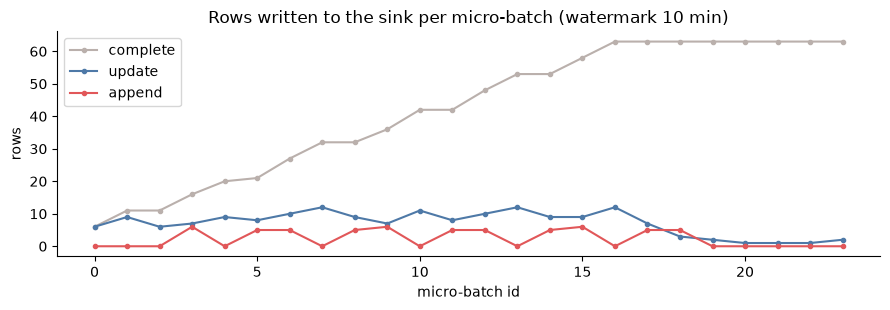

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for mode, c in [("complete", "#BAB0AC"), ("update", "#4E79A7"), ("append", "#E15759")]:
    per_batch = results[mode].groupby("batch_id").size().reindex(range(max(s["batches"] for s in stats)), fill_value=0)
    ax.plot(per_batch.index, per_batch.values, marker="o", ms=3, label=mode, color=c)
ax.set(title="Rows written to the sink per micro-batch (watermark 10 min)", xlabel="micro-batch id", ylabel="rows")
ax.legend(); plt.tight_layout(); plt.show()

*Insight: The three modes read the same rows but write very different amounts. `append` suits sinks that cannot
update rows (files, Kafka); `update` suits key-value or Delta MERGE sinks; `complete` suits small dashboards only.*

## 3. Late Data: Two Watermark Delays

A short watermark delay gives final results sooner and keeps less state, but drops more late rows. A long delay
keeps more data and more state. The cell runs the `update` query with 10 and 30 minutes and compares the final
counts with the batch ground truth.

In [6]:
rows = []
for delay in ["10 minutes", "30 minutes"]:
    emitted, s, progress = run(f"late-{delay.split()[0]}m", windowed(INPUT, delay), "update")   # new checkpoint per query
    view = final_view(emitted)
    state_rows = max(p["stateOperators"][0]["numRowsTotal"] for p in progress if p["stateOperators"])
    rows.append({"watermark": delay, "trips counted": int(view.sum()), "ground truth": int(truth.sum()),
                 "missing": int(truth.sum() - view.sum()), "dropped (progress metric)": s["dropped late"],
                 "max state rows": state_rows})
late_tbl = pd.DataFrame(rows)
print(late_tbl.to_string(index=False))
print(f"delayed trips in the input: {late.sum():,} (delay 5-60 min); "
      f"delayed > 10 min: {(trips.late_min > 10).sum():,}, > 30 min: {(trips.late_min > 30).sum():,}")

 watermark  trips counted  ground truth  missing  dropped (progress metric)  max state rows
10 minutes          12851         13169      318                         60              16
30 minutes          13115         13169       54                         18              21
delayed trips in the input: 755 (delay 5-60 min); delayed > 10 min: 695, > 30 min: 413


With a 10-minute watermark, 318 trips (2.4 %) are missing; with 30 minutes only 54. The longer delay keeps more
state (21 instead of 16 window rows at the peak). The progress metric `numRowsDroppedByWatermark` is smaller than
`missing` (60 and 18), because Spark drops late data at the state operator, **after** the partial aggregation:
one dropped row there is a partial count of several trips for one window and borough.

Not every delayed trip is dropped: 695 trips are more than 10 minutes late, but only 318 are dropped. A trip is
dropped only if its pickup time is older than the watermark of the micro-batch that reads it, and the watermark
(the newest event time of the **previous** batches minus the delay) moves only at micro-batch boundaries.

*Insight: The watermark delay is a business decision: how late may data be and still count? Measure the delay
distribution of your source first (here: up to 60 minutes) and choose the watermark from it, or route late rows to a
separate correction job.*

## 4. Checkpoints and Restart

The **checkpoint** folder stores which files each micro-batch read (the offset log), which batches finished (the
commit log), and the window state. After a restart with the same checkpoint, Spark continues where it stopped:

- The file source remembers the processed files, so it reads only new files.
- A batch that failed before its commit is re-run with the **same** batch id and the same files.
- With an **idempotent sink** (writing the batch again gives the same result), this is exactly-once end to end.

The sink below writes each micro-batch to its own folder `batch_id=<n>` with `mode("overwrite")`: a re-run of a
batch replaces its output and never duplicates it. `trigger(availableNow=True)` processes all files that exist at
start (still one file per micro-batch here) and then **stops** by itself: a batch-style incremental job, for example
started by an orchestrator every hour.

In [7]:
INC, OUT, CHK = WORK / "input-inc", WORK / "sink", WORK / "chk" / "incremental"

def parquet_sink(batch, batch_id):
    batch.write.mode("overwrite").parquet(str(OUT / f"batch_id={batch_id}"))

def incremental_run() -> dict:
    q = (windowed(INC, "30 minutes").writeStream.outputMode("append").foreachBatch(parquet_sink)
         .option("checkpointLocation", str(CHK)).trigger(availableNow=True).start())
    q.awaitTermination()                           # availableNow stops by itself
    prog = q.recentProgress
    return {"batches": len(prog), "input rows": sum(p["numInputRows"] for p in prog),
            "files read": sum(1 for p in prog if p["numInputRows"] > 0)}

deliver(INC, range(0, 12))                         # 07:00-09:00 arrived
run1 = incremental_run()
deliver(INC, range(12, N_FILES))                   # the rest arrives later
run2 = incremental_run()
run3 = incremental_run()                           # nothing new
rows_by_file = trips.groupby("file_no").size()
print(pd.DataFrame([run1, run2, run3], index=["run 1 (files 0-11)", "run 2 (new files)", "run 3 (no new files)"]))
print("rows in files 0-11:", rows_by_file.loc[0:11].sum(), "| rows in later files:", rows_by_file.loc[12:].sum())
print("checkpoint folders:", sorted(p.name for p in CHK.iterdir()))
print("committed batches:", len(list((CHK / "commits").glob("[0-9]*"))))

                      batches  input rows  files read
run 1 (files 0-11)         13        8295          12
run 2 (new files)          12        4874          12
run 3 (no new files)        1           0           0
rows in files 0-11: 8295 | rows in later files: 4874
checkpoint folders: ['.metadata.crc', 'commits', 'metadata', 'offsets', 'sources', 'state']
committed batches: 25


In [8]:
# the incremental runs must give the same windows as one uninterrupted run with the same settings
inc_result = spark.read.parquet(str(OUT)).toPandas()
one_go, s_one, _ = run("append-30m", windowed(INPUT, "30 minutes"), "append")
key = ["window_start", "Borough", "trips", "revenue"]
same = (inc_result[key].sort_values(key[:2]).reset_index(drop=True)
        .equals(one_go[key].sort_values(key[:2]).reset_index(drop=True)))
print(f"incremental (3 restarts): {len(inc_result)} windows | one uninterrupted run: {len(one_go)} windows | "
      f"identical: {same}")
print(f"duplicate (window, borough) rows in the sink: {inc_result.duplicated(['window_start', 'Borough']).sum()}")

incremental (3 restarts): 48 windows | one uninterrupted run: 48 windows | identical: True
duplicate (window, borough) rows in the sink: 0


*Insight: The second run read only the new files and the third run read nothing, yet the windows that were still
open at the first stop were completed correctly in the second run: the checkpoint also stores the window state.
The result equals one uninterrupted run, without duplicates.*

## 5. Notes for Production

| topic | practice |
| :--- | :--- |
| trigger | default (as fast as possible), `processingTime="1 minute"`, `availableNow=True` for scheduled incremental jobs |
| tests / notebooks | `processAllAvailable()` waits until all available input is processed: deterministic results |
| state store | default HDFS-backed (in memory + checkpoint files); `RocksDBStateStoreProvider` for large state |
| file source | many small files are slow to list; use `maxFilesPerTrigger` / `maxBytesPerTrigger`, or Auto Loader / Kafka |
| sinks | file and Delta sinks are exactly-once; in `foreachBatch`, make the write idempotent (overwrite by batch id, or MERGE) |
| monitoring | `query.lastProgress`: input rows per second, batch duration, state rows, rows dropped by watermark |

## Real-World Use Case or Analogy

A teacher collects homework every 10 minutes from a tray. The **watermark** is the rule "homework that is more
than 30 minutes late is not graded any more". `append` is a final grade for each assignment once the deadline is
over; `update` is a live grade book; `complete` is printing the whole grade book after every collection. The
**checkpoint** is the teacher's notebook of which papers are already graded, so after a break nothing is graded
twice and nothing is missed.

Companies use Structured Streaming to load files that land in cloud storage (application logs, exports from
partners, IoT data) into Delta tables every few minutes, with `availableNow` jobs started by Airflow or Databricks
Jobs. The same pattern computes near-real-time aggregates such as orders per minute or trips per zone.

In [9]:
for q in spark.streams.active:
    q.stop()
spark.stop()